# №3 зертханалық жұмыс
## Сызықтық, полиномдық және логистикалық регрессия модельдерін құру және бағалау.

Мақсат: модель пішінін, бағдарламалық көрінісін, коэффициенттерін және тексерілетін сапаны салыстыру. Қатысты материалдар: 3-тарау, 3.9–3.10-бөлімдер; `lab03.py` скрипті.

Бірінші тәжірибе тек айқын синтетикалық деректерді, екіншісі ашық UCI Wine жиынтығын қолданады. Орта орнатылғаннан кейін барлық есептеу жергілікті орындалады. Графиктер мен CSV файлдары `lab03_artifacts` ішінде сақталады. Таза ядрода ұяшықтарды жоғарыдан төмен қарай іске қосыңыз. Сақталған шығыстар әмбебап күтілетін дәлдікті емес, нақты тексерілген есептеуді көрсетеді.

### 1–3-қадамдар. Орта және бекітілген хаттама
Синтетикалық деректер үшін: [−3,3] аралығындағы 500 тәуелсіз x, `y=4+2*x+1.5*x**2+Normal(0,1.2)`, seed 2026. Бөлу 80/20, random_state 2026. Dummy, x бойынша түзу және 2 дәреже алдын ала салыстырылады. Test дәрежені таңдауға қолданылмайды.

Wine үшін: стратификацияланған 80/20, random_state 2026; оқыту жиіліктері бар Dummy және StandardScaler–LogisticRegression(max_iter=2000). Метрикалар нәтижені қарауға дейін бекітілген.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, f1_score, log_loss, confusion_matrix)

ROOT = Path.cwd() / "lab03_artifacts"
FIGURES = ROOT / "figures"
DATASETS = ROOT / "datasets"
FIGURES.mkdir(parents=True, exist_ok=True)
DATASETS.mkdir(parents=True, exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"


from IPython.display import display, Image
from importlib.metadata import version
for package in ("numpy", "pandas", "scikit-learn", "matplotlib"):
    print(package, version(package))


numpy 2.5.4
pandas 3.0.1
scikit-learn 1.9.1
matplotlib 3.11.2


### 4–6-қадамдар. Сандық болжам және коэффициенттерді қайтару
PolynomialFeatures x пен x² жасайды; include_bias=False артық тұрақты бағанды алып тастайды. Масштабтау split орындалғаннан кейін оқытылады. Салмақтар `w=beta/scale`, `b=b_z−sum(beta*mean/scale)` ережесімен бастапқы базиске қайтарылады.

Орындаудан бұрын x=−2,0,2 үшін генератордың орташа мәндерін есептеңіз: олар 6,4,14. Жеке жауаптарда қосымша шу бар.

      model      MAE     RMSE        R2
      Dummy 4.070267 5.155161 -0.015380
     Linear 3.759476 4.481323  0.232715
Polynomial2 1.164036 1.419650  0.922997
Сызықтық модель: b,w 8.276661685333577 [2.11064898]
Бастапқы базистегі квадраттық модель: b,w1,w2 3.9287330958057387 1.9459009431933074 1.543410647487557
x=-2,0,2 кезіндегі болжамдар {'Dummy': [8.427192697593576, 8.427192697593576, 8.427192697593576], 'Linear': [4.055363724038848, 8.276661685333577, 12.497959646628306], 'Polynomial2': [6.210573799369351, 3.9287330958057387, 13.994177572142581]}


Стандартталған салмақтар [3.2675017893908995, 3.982161983321012]
Орташа мәндер мен масштабтар [0.0713197758794685, 2.8247040991537524] [1.6791716972133166, 2.580105294597636]


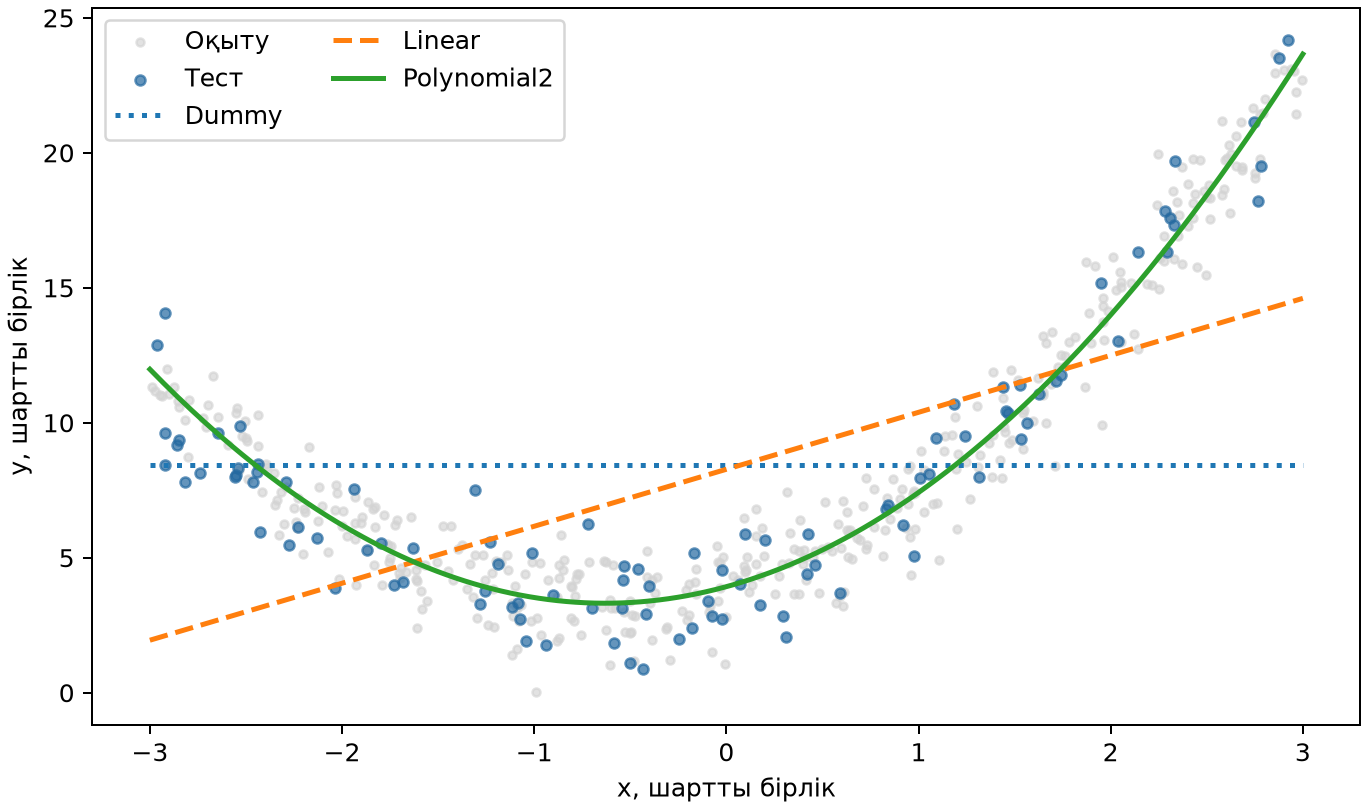

In [2]:
def polynomial_experiment():
    rng = np.random.default_rng(2026)
    X = pd.DataFrame({"x": rng.uniform(-3, 3, 500)})
    x = X["x"].to_numpy()
    y = 4 + 2*x + 1.5*x**2 + rng.normal(0, 1.2, 500)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, random_state=2026)
    models = {"Dummy": DummyRegressor(strategy="mean"),
              "Linear": LinearRegression(),
              "Polynomial2": Pipeline([
                  ("poly", PolynomialFeatures(degree=2, include_bias=False)),
                  ("scale", StandardScaler()), ("model", LinearRegression())])}
    rows = []
    for name, model in models.items():
        model.fit(Xtr, ytr)
        pred = model.predict(Xte)
        rows.append({"model": name, "MAE": mean_absolute_error(yte, pred),
                     "RMSE": np.sqrt(mean_squared_error(yte, pred)), "R2": r2_score(yte, pred)})
    scaler, reg = models["Polynomial2"].named_steps["scale"], models["Polynomial2"].named_steps["model"]
    coefficient = reg.coef_ / scaler.scale_
    intercept = float(reg.intercept_ - np.dot(reg.coef_, scaler.mean_ / scaler.scale_))
    probe = pd.DataFrame({"x": [-2., 0., 2.]})
    predictions = {name: model.predict(probe).tolist() for name, model in models.items()}
    print(pd.DataFrame(rows).to_string(index=False))
    print("Сызықтық модель: b,w", models["Linear"].intercept_, models["Linear"].coef_)
    print("Бастапқы базистегі квадраттық модель: b,w1,w2", intercept, *coefficient)
    print("x=-2,0,2 кезіндегі болжамдар", predictions)
    grid = pd.DataFrame({"x": np.linspace(-3, 3, 250)})
    fig, ax = plt.subplots(figsize=(7.6, 4.5), layout="constrained")
    ax.scatter(Xtr["x"], ytr, s=10, color="lightgray", label="Оқыту", alpha=.65)
    ax.scatter(Xte["x"], yte, s=16, color="#2469A0", label="Тест", alpha=.7)
    for name, style in [("Dummy", ":"), ("Linear", "--"), ("Polynomial2", "-")]:
        ax.plot(grid["x"], models[name].predict(grid), style, linewidth=2, label=name)
    ax.set(xlabel="x, шартты бірлік", ylabel="y, шартты бірлік")
    ax.legend(ncol=2)
    fig.savefig(FIGURES / "ch03_05_polynomial.png", dpi=180)
    plt.close(fig)
    X.assign(y_synthetic=y).to_csv(DATASETS / "synthetic_quadratic_regression.csv", index=False)
    return {"synthetic": True, "seed": 2026, "rows": 500, "train_size": len(ytr),
            "test_size": len(yte), "metrics": rows,
            "linear_coefficients": {"intercept": float(models["Linear"].intercept_),
                                    "x": float(models["Linear"].coef_[0])},
            "polynomial_original_basis": {"intercept": intercept, "x": float(coefficient[0]),
                                          "x_squared": float(coefficient[1])},
            "polynomial_standardized_coefficients": reg.coef_.tolist(),
            "polynomial_standardized_intercept": float(reg.intercept_),
            "polynomial_scaler_mean": scaler.mean_.tolist(),
            "polynomial_scaler_scale": scaler.scale_.tolist(),
            "probe_x": probe["x"].tolist(), "probe_predictions": predictions,
            "probe_generator_mean": [6., 4., 14.]}


polynomial_result = polynomial_experiment()
print("Стандартталған салмақтар", polynomial_result["polynomial_standardized_coefficients"])
print("Орташа мәндер мен масштабтар", polynomial_result["polynomial_scaler_mean"], polynomial_result["polynomial_scaler_scale"])
display(Image(filename=str(FIGURES / "ch03_05_polynomial.png")))


Алынған полиномдық формула шамамен `3.928733+1.945901*x+1.543411*x²`. x=2 кезінде оның үлестері 3.928733, 3.891802 және 6.173643; қосындысы 13.994178. Тестте түзудің RMSE мәні 4.481323, 2 дәреженікі — 1.419650.

**Сіздің жауабыңыз.** Түзудің жеткіліксіздігін, масштабталған және бастапқы салмақтардың айырмасын, басқа механизм не экстраполяция үшін қорытынды шегін түсіндіріңіз.

_Өз есебіңіз бен түсіндірмеңізді жазыңыз._

### 7-қадам. Wine дереккөзі және сипаттамасы
Wine жиынтығында 178 үлгі, 13 химиялық белгі және үш класс бар. Дереккөз: Aeberhard, S. & Forina, M. (1992), UCI, [DOI 10.24432/C5PC7J](https://doi.org/10.24432/C5PC7J), [деректер беті](https://archive.ics.uci.edu/dataset/109/wine), CC BY 4.0. Кіріктірілген көшірмеде бастапқы 1–3 орнына 0–2 белгілері қолданылады. CSV экспортында бөлек атрибуция сақталады. Бұл сапа рейтингін емес, шығу тегі топтарын жіктеу.

In [3]:
wine_data = load_wine(as_frame=True)
print("X өлшемі:", wine_data.data.shape)
print("Кластар:", wine_data.target.value_counts().sort_index().to_dict())
print("Жетіспейтін мәндер:", int(wine_data.frame.isna().sum().sum()))
print("Белгі атаулары:", wine_data.feature_names)
display(wine_data.frame.head())


X өлшемі: (178, 13)
Кластар: {0: 59, 1: 71, 2: 48}
Жетіспейтін мәндер: 0
Белгі атаулары: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


### 8–9-қадамдар. Кластар, ықтималдықтар және коэффициенттер
Тестте 36 нысан бар. DummyClassifier(prior) train жиілік үлестірімін береді. Логистикалық модель Accuracy, F1-macro және log loss бойынша бағаланады; матрица мен үш ықтималдық жауабы бөлек қарастырылады. 0 және 1 кластары үшін alcohol салмақтарының айырмасы қалған стандартталған белгілер өзгермегендегі p0/p1 қатынасының логарифмі арқылы түсіндіріледі.

Wine: (178, 13) кластар {0: 59, 1: 71, 2: 48}
     model  accuracy  F1macro  log_loss
DummyPrior  0.388889 0.186667  1.089706
  Logistic  0.972222 0.974321  0.084741
Logistic матрицасы [[12, 0, 0], [1, 13, 0], [0, 0, 10]]
                                class0    class1    class2
alcohol                       0.747982 -0.877191  0.129208
malic_acid                    0.216501 -0.440284  0.223783
ash                           0.349549 -0.643603  0.294054
alcalinity_of_ash            -0.616379  0.353771  0.262608
magnesium                     0.266616 -0.173408 -0.093208
total_phenols                 0.349449 -0.155438 -0.194011
flavanoids                    0.523619  0.437362 -0.960981
nonflavanoid_phenols         -0.270286  0.229121  0.041165
proanthocyanins               0.193501  0.225934 -0.419434
color_intensity               0.104063 -1.014658  0.910595
hue                           0.171233  0.549485 -0.720718
od280/od315_of_diluted_wines  0.700359  0.014571 -0.714930
proline    

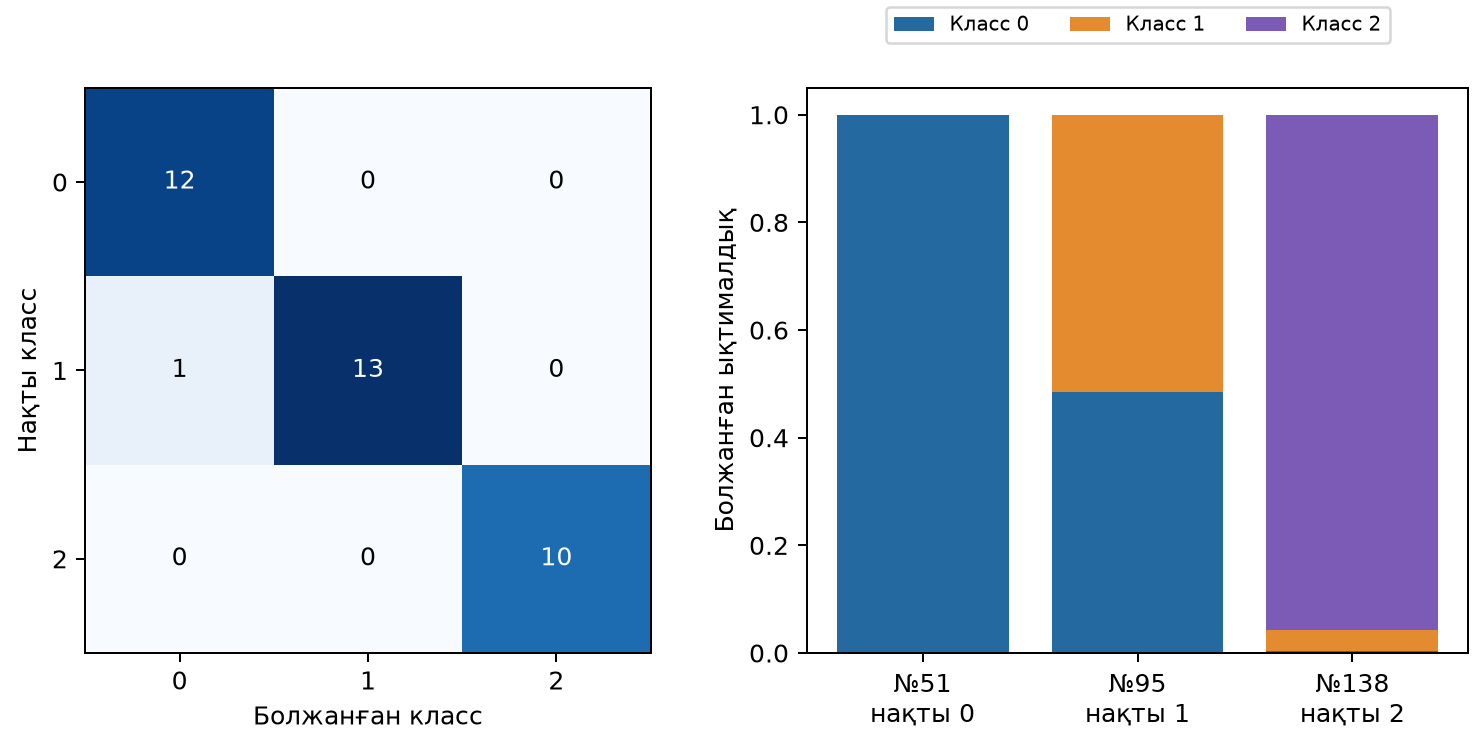

In [4]:
def wine_experiment():
    data = load_wine(as_frame=True)
    X, y = data.data, data.target
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, random_state=2026, stratify=y)
    models = {"DummyPrior": DummyClassifier(strategy="prior"),
              "Logistic": Pipeline([("scale", StandardScaler()),
                                     ("model", LogisticRegression(max_iter=2000))])}
    rows, matrices = [], {}
    for name, model in models.items():
        model.fit(Xtr, ytr)
        pred, proba = model.predict(Xte), model.predict_proba(Xte)
        rows.append({"model": name, "accuracy": accuracy_score(yte, pred),
                     "F1macro": f1_score(yte, pred, average="macro"),
                     "log_loss": log_loss(yte, proba, labels=model.classes_)})
        matrices[name] = confusion_matrix(yte, pred, labels=[0, 1, 2]).tolist()
    model = models["Logistic"]
    reg, scaler = model.named_steps["model"], model.named_steps["scale"]
    positions = [int(np.flatnonzero(yte.to_numpy()==k)[0]) for k in range(3)]
    probe = Xte.iloc[positions]
    predicted, probabilities = model.predict(probe), model.predict_proba(probe)
    examples = [{"row_id": int(probe.index[i]), "true_class": int(yte.iloc[positions[i]]),
                 "predicted_class": int(predicted[i]), "probabilities": probabilities[i].tolist()}
                for i in range(3)]
    alcohol_index = data.feature_names.index("alcohol")
    contrast = float(reg.coef_[0, alcohol_index] - reg.coef_[1, alcohol_index])
    print("Wine:", X.shape, "кластар", y.value_counts().sort_index().to_dict())
    print(pd.DataFrame(rows).to_string(index=False))
    print("Logistic матрицасы", matrices["Logistic"])
    print(pd.DataFrame(reg.coef_.T, index=data.feature_names, columns=["class0", "class1", "class2"]).round(6))
    print("Ықтималдық мысалдары", examples)
    print("alcohol0-1 айырмасы және exp(айырма)", contrast, np.exp(contrast))
    fig, axs = plt.subplots(1, 2, figsize=(8.2, 4.1), layout="constrained")
    matrix = np.array(matrices["Logistic"])
    axs[0].imshow(matrix, cmap="Blues", vmin=0)
    axs[0].set(xticks=range(3), yticks=range(3), xlabel="Болжанған класс", ylabel="Нақты класс")
    for i in range(3):
        for j in range(3):
            axs[0].text(j, i, str(matrix[i,j]), ha="center", va="center",
                        color="white" if matrix[i,j]>matrix.max()/2 else "black")
    bottom = np.zeros(3)
    for k, color in enumerate(["#2469A0", "#E48B30", "#7C5BB6"]):
        axs[1].bar(range(3), probabilities[:,k], bottom=bottom, color=color, label=f"Класс {k}")
        bottom += probabilities[:,k]
    axs[1].set(xticks=range(3), xticklabels=[f"№{r['row_id']}\nнақты {r['true_class']}" for r in examples],
               ylim=(0,1.05), ylabel="Болжанған ықтималдық")
    axs[1].legend(loc="upper center", bbox_to_anchor=(.5,1.16), ncol=3, fontsize=8)
    fig.savefig(FIGURES / "ch03_06_logistic.png", dpi=180)
    plt.close(fig)
    data.frame.to_csv(DATASETS / "wine_sklearn.csv", index=False)
    attribution = ("Wine. Aeberhard, S. & Forina, M. (1992). UCI Machine Learning Repository.\n"
                   "DOI: https://doi.org/10.24432/C5PC7J\n"
                   "Source: https://archive.ics.uci.edu/dataset/109/wine\n"
                   "License: CC BY 4.0 https://creativecommons.org/licenses/by/4.0/\n"
                   "Copy exported from sklearn.datasets.load_wine; labels 1-3 represented as 0-2; column names follow scikit-learn.\n"
                   "No synthetic observations added; access/metadata check: 2026-11-04.\n")
    (DATASETS / "Wine_Attribution.txt").write_text(attribution, encoding="utf-8")
    return {"synthetic": False, "dataset": "UCI Wine", "rows": len(X), "features": X.shape[1],
            "class_counts": y.value_counts().sort_index().tolist(), "train_size": len(ytr), "test_size": len(yte),
            "train_class_counts": ytr.value_counts().sort_index().tolist(),
            "test_class_counts": yte.value_counts().sort_index().tolist(),
            "metrics": rows, "confusion_matrices": matrices, "feature_names": data.feature_names,
            "standardized_coefficients": reg.coef_.tolist(), "standardized_intercepts": reg.intercept_.tolist(),
            "original_coefficients": (reg.coef_/scaler.scale_).tolist(),
            "original_intercepts": (reg.intercept_-reg.coef_@(scaler.mean_/scaler.scale_)).tolist(),
            "scaler_mean": scaler.mean_.tolist(), "scaler_scale": scaler.scale_.tolist(),
            "examples": examples, "alcohol_contrast_class0_class1": contrast,
            "alcohol_odds_ratio_per_train_sd": float(np.exp(contrast)),
            "probabilities_sum_to_one": bool(np.allclose(probabilities.sum(axis=1),1))}


wine_result = wine_experiment()
display(Image(filename=str(FIGURES / "ch03_06_logistic.png")))


Тексерілген бөлуде 36 нысанның 35-і дұрыс танылды. 95 жолы үшін ықтималдықтар шамамен [0.484246,0.515554,0.000200], нақты класс 1. Белгі дұрыс болса да, оның log loss қосындысына қосатын үлесі шамамен 0.662514. alcohol0−alcohol1 салмақтары 1.625173 береді, p0/p1 көбейткіші бір оқыту стандартты ауытқуына шамамен 5.079297.

**Сіздің жауабыңыз.** Матрицаның бір қатесін, 95 жолының сақ дұрыс болжамын және модельдегі айырманың үлгіге себептік әрекет жасаудан өзгешелігін түсіндіріңіз.

_Өз түсіндірмеңізді жазыңыз._

### Сандық өзін-өзі тексеру
Өлшемдер, ашып жазылған формула мен сақталған болжамдардың теңдігі, коэффициенттер құрылымы, ықтималдықтар қосындысы және қателер матрицасының сәйкестігі тексеріледі. Тексеру басқа нұсқаларда не өзгертілген деректерде метрикалардың әмбебап сәйкес келуін талап етпейді.

In [5]:
p = polynomial_result
assert p["synthetic"] and p["rows"] == 500
assert (p["train_size"], p["test_size"]) == (400, 100)
coef = p["polynomial_original_basis"]
probe_x = np.asarray(p["probe_x"])
expanded = coef["intercept"] + coef["x"]*probe_x + coef["x_squared"]*probe_x**2
assert np.allclose(expanded, p["probe_predictions"]["Polynomial2"])
assert np.allclose(4+2*probe_x+1.5*probe_x**2, p["probe_generator_mean"])
assert not wine_result["synthetic"] and wine_result["features"] == 13
assert (wine_result["train_size"], wine_result["test_size"]) == (142, 36)
assert np.asarray(wine_result["standardized_coefficients"]).shape == (3, 13)
for matrix in wine_result["confusion_matrices"].values():
    assert np.asarray(matrix).shape == (3, 3) and np.asarray(matrix).sum() == 36
assert wine_result["probabilities_sum_to_one"]
for sample in wine_result["examples"]:
    assert np.isclose(sum(sample["probabilities"]), 1)
    assert np.argmax(sample["probabilities"]) == sample["predicted_class"]
print("Өлшемдер, формула және ықтималдықтар бойынша өзін-өзі тексеру орындалды.")


Өлшемдер, формула және ықтималдықтар бойынша өзін-өзі тексеру орындалды.


### Жеке нұсқалар
Міндетті негізгі тәжірибені сақтаңыз. Баптау таңдау үшін train бойынша бөлек ішкі тексеру қажет; бастапқы test біртіндеп жақсартуға қолданылмайды.

1. Синтетикалық шуды 2,4 шамасына арттыру.
2. x ауқымын [−1,5;1,5] аралығына тарылту.
3. Алдын ала таңдалған он нүктеде формула мен конвейерді тексеру.
4. Wine жиынтығында alcohol және proline белгілерін қалдырып, ақпарат азаюын ішкі валидацияда зерттеу.
5. Wine жиынтығында масштабтау бар және жоқ нұсқаларды ішкі тексеруде салыстыру.
6. Ішкі тексерудің сенімділігі ең аз үш ықтималдық жауабын талдау.

**Сіздің нөміріңіз, сұрағыңыз, хаттамаңыз және қорытындыңыз.**

_Өз түсіндірмелеріңіз бен кодыңызды қосыңыз._

### 10-қадам. Есеп және қорғау
Есеп: қойылымдар, дереккөз және лицензия, генератор, split, формулалар, коэффициенттер, екі кесте, екі график, ықтималдықтар, қателер, нұсқалар және таза қайта іске қосу.

Жергілікті рубрика: қойылым мен дереккөздер 15%; split және Pipeline 20%; регрессия 20%; қолмен тексеру 15%; жіктеу мен ықтималдықтар 20%; нәтижені қайталау мүмкіндігі 10%. Толықтықтың жиыны 100%; ресми балдарды силлабус пен оқытушы белгілейді.

Бақылау сұрақтары: параметрлерге қатысты сызықтылық; include_bias; салмақтардың бірліктері; b және w шамаларын қайтару; орташа және шулы жауап; дәреже таңдау; prior; ықтималдықтар максимумы; log loss; екі логистикалық салмақтың айырмасы.

Әдістемелік негіз: Оспан Ә.Ғ. авторлық 3-дәрісі мен 3-зертханалық жұмысы. API: [PolynomialFeatures](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html), [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [load_wine](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html). 2026 жылғы 4 қарашада тексерілген.